In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50, resnet18, resnet101
from torch.utils.data import Dataset, DataLoader
from pycocotools.coco import COCO
import torchvision.transforms as T
from PIL import Image
import numpy as np
import os
import time
from tqdm import tqdm
from scipy.optimize import linear_sum_assignment
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pycocotools.coco import COCO
from PIL import Image
from tqdm import tqdm
from scipy.optimize import linear_sum_assignment
import numpy as np

In [9]:

# -------------------------------
# Positional Encoding
# -------------------------------
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = pe.unsqueeze(1)

    def forward(self, x):
        return x + self.pe[:x.size(0)].to(x.device)

# -------------------------------
# DETR Architecture
# -------------------------------
class DETR(nn.Module):
    def __init__(self, num_classes, hidden_dim=256, nheads=8, num_encoder_layers=6, num_decoder_layers=6):
        super().__init__()
        backbone = resnet50(pretrained=True)
        self.backbone = nn.Sequential(*list(backbone.children())[:-2])
        self.input_proj = nn.Conv2d(2048, hidden_dim, kernel_size=1)
        self.pos_encoder = PositionalEncoding(hidden_dim)
        self.query_pos = nn.Parameter(torch.rand(100, hidden_dim))
        self.transformer = nn.Transformer(d_model=hidden_dim, nhead=nheads,
                                          num_encoder_layers=num_encoder_layers, num_decoder_layers=num_decoder_layers)
        self.class_embed = nn.Linear(hidden_dim, num_classes + 1)
        self.bbox_embed = nn.Linear(hidden_dim, 4)

    def forward(self, x):
        x = self.backbone(x)
        x = self.input_proj(x)
        bs, c, h, w = x.shape
        x = x.flatten(2).permute(2, 0, 1)
        x = self.pos_encoder(x)
        query = self.query_pos.unsqueeze(1).repeat(1, bs, 1)
        tgt = torch.zeros_like(query)
        hs = self.transformer(x, tgt).transpose(0, 1)
        logits = self.class_embed(hs)
        boxes = self.bbox_embed(hs).sigmoid()
        return {'pred_logits': logits, 'pred_boxes': boxes}

# -------------------------------
# Hungarian Matcher
# -------------------------------
class HungarianMatcher(nn.Module):
    def __init__(self, class_cost=1, bbox_cost=5):
        super().__init__()
        self.class_cost = class_cost
        self.bbox_cost = bbox_cost

    def forward(self, outputs, targets):
        bs, num_queries = outputs["pred_logits"].shape[:2]
        out_prob = outputs["pred_logits"].softmax(-1)
        out_bbox = outputs["pred_boxes"]
        indices = []
    
        for b in range(bs):
            tgt_ids = targets[b]["labels"]
            tgt_bbox = targets[b]["boxes"]
            cost_class = -out_prob[b][:, tgt_ids]
            cost_bbox = torch.cdist(out_bbox[b], tgt_bbox, p=1)
    
            cost = self.class_cost * cost_class + self.bbox_cost * cost_bbox
            i, j = linear_sum_assignment(cost.cpu().detach())  # ✅ FIXED HERE
            indices.append((torch.as_tensor(i, dtype=torch.int64), torch.as_tensor(j, dtype=torch.int64)))
    
        return indices


# -------------------------------
# Custom COCO Dataset
# -------------------------------
class CocoDetectionDataset(Dataset):
    def __init__(self, img_folder, ann_file):
        self.coco = COCO(ann_file)
        self.ids = list(sorted(self.coco.imgs.keys()))
        self.root = img_folder
        self.transforms = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406],
                                 [0.229, 0.224, 0.225])
        ])

    def __getitem__(self, index):
        img_id = self.ids[index]
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)
        img_file = self.coco.loadImgs(img_id)[0]['file_name']
        path = os.path.join(self.root, img_file)
        img = Image.open(path).convert("RGB")
        w, h = img.size

        boxes = []
        labels = []
        for ann in anns:
            x, y, bw, bh = ann["bbox"]
            boxes.append([x / w, y / h, bw / w, bh / h])
            labels.append(ann["category_id"] - 1)

        boxes = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        target = {"boxes": boxes, "labels": labels}
        return self.transforms(img), target

    def __len__(self):
        return len(self.ids)

# -------------------------------
# Loss Function
# -------------------------------
def detr_loss(outputs, targets, matcher, num_classes=2):
    indices = matcher(outputs, targets)
    src_logits = outputs['pred_logits']
    src_boxes = outputs['pred_boxes']

    target_classes = torch.full(src_logits.shape[:2], num_classes, dtype=torch.int64, device=src_logits.device)
    for i, (src_idx, tgt_idx) in enumerate(indices):
        target_classes[i, src_idx] = targets[i]['labels'][tgt_idx]

    loss_ce = F.cross_entropy(src_logits.transpose(1, 2), target_classes)

    pred_boxes = torch.cat([src_boxes[i][src] for i, (src, _) in enumerate(indices)], dim=0)
    tgt_boxes = torch.cat([t['boxes'][tgt] for t, (_, tgt) in zip(targets, indices)], dim=0)

    loss_bbox = F.l1_loss(pred_boxes, tgt_boxes, reduction='mean')
    return loss_ce + loss_bbox

# -------------------------------
# Training Function
# -------------------------------
def train_fn(data_loader, model, criterion, optimizer, device, scheduler, epoch, matcher):
    model.train()
    loop = tqdm(data_loader, desc=f"Epoch [{epoch+1}]")
    total_loss = 0
    for imgs, targets in loop:
        imgs = torch.stack(imgs).to(device)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        outputs = model(imgs)
        loss = criterion(outputs, targets, matcher, num_classes=2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler:
            scheduler.step()
        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())
    print(f"Epoch {epoch+1} completed with avg loss: {total_loss / len(data_loader):.4f}")



class AverageMeter:
    def __init__(self):
        self.reset()
    
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

# -------------------------------
# Evaluation Function
# -------------------------------
def eval_fn(data_loader, model, criterion, device, matcher, num_classes=2):
    model.eval()
    summary_loss = AverageMeter()

    with torch.no_grad():
        loop = tqdm(data_loader, desc="Validation")
        for imgs, targets in loop:
            imgs = torch.stack(imgs).to(device)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            outputs = model(imgs)
            loss = criterion(outputs, targets, matcher, num_classes=num_classes)

            summary_loss.update(loss.item(), len(imgs))
            loop.set_postfix(loss=summary_loss.avg)

    print(f"Validation Loss: {summary_loss.avg:.4f}")
    return summary_loss

In [5]:
# Config
img_dir = 'C:/Users/mza0288/Datset/train2017'
ann_file = 'C:/Users/mza0288/Datset/annotations/instances_train2017.json'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Model and Dataset
model = DETR(num_classes=2).to(device)
matcher = HungarianMatcher()
dataset = CocoDetectionDataset(img_dir, ann_file)
dataloader = DataLoader(dataset, batch_size=16, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))

# Optimizer and Train
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = None

for epoch in range(10):
    train_fn(dataloader, model, detr_loss, optimizer, device, scheduler, epoch, matcher)

# Save
torch.save(model.state_dict(), 'custom_detr_instance_seg.pth')


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


Epoch [1]: 100%|█████████████████████████████████████████████████████████| 104/104 [04:01<00:00,  2.32s/it, loss=0.228]


Epoch 1 completed with avg loss: 0.2895


Epoch [2]: 100%|█████████████████████████████████████████████████████████| 104/104 [03:28<00:00,  2.01s/it, loss=0.217]


Epoch 2 completed with avg loss: 0.2236


...

Epoch 8 completed with avg loss: 0.1960


Epoch [9]: 100%|█████████████████████████████████████████████████████████| 104/104 [03:58<00:00,  2.29s/it, loss=0.204]


Epoch 9 completed with avg loss: 0.1942


Epoch [10]: 100%|████████████████████████████████████████████████████████| 104/104 [03:30<00:00,  2.03s/it, loss=0.184]

Epoch 10 completed with avg loss: 0.1921


In [8]:
# Run evaluation after training or between epochs
# Define validation dataset and dataloader
val_dataset = CocoDetectionDataset(
    img_folder="C:/Users/mza0288/Datset/val2017", 
    ann_file="C:/Users/mza0288/Datset/annotations/instances_val2017.json"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=lambda x: tuple(zip(*x))
)

val_loss = eval_fn(val_loader, model, detr_loss, device, matcher, num_classes=2)

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


Validation: 100%|████████████████████████████████████████████████████████| 351/351 [02:01<00:00,  2.89it/s, loss=0.248]

Validation Loss: 0.2482


In [12]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from torch.utils.data import DataLoader

def view_predictions(dataset, model, device, sample_index=0, conf_threshold=0.5):
    model.eval()
    data_loader = DataLoader(dataset, batch_size=1, shuffle=False, collate_fn=lambda x: tuple(zip(*x)))

    images, targets = next(iter(data_loader))
    image_tensor = images[sample_index].to(device)
    target = {k: v.to(device) for k, v in targets[sample_index].items()}
    h, w = image_tensor.shape[1:]  # Height and width for denormalization

    with torch.no_grad():
        outputs = model(image_tensor.unsqueeze(0))

    pred_logits = outputs['pred_logits'][0].softmax(-1).detach().cpu().numpy()
    pred_boxes = outputs['pred_boxes'][0].detach().cpu().numpy()

    # Filter predictions with score threshold
    scores = pred_logits[:, :-1].max(-1)
    keep = scores > conf_threshold
    pred_boxes = pred_boxes[keep]
    pred_boxes[:, [0, 2]] *= w
    pred_boxes[:, [1, 3]] *= h
    pred_boxes = pred_boxes.astype(np.int32)

    # Ground truth boxes
    tgt_boxes = target['boxes'].detach().cpu().numpy()
    tgt_boxes[:, [0, 2]] *= w
    tgt_boxes[:, [1, 3]] *= h
    tgt_boxes = tgt_boxes.astype(np.int32)

    # Convert image to valid uint8 OpenCV format
    image_np = image_tensor.permute(1, 2, 0).cpu().numpy()
    image_np = (image_np * np.array([0.229, 0.224, 0.225]) +
                np.array([0.485, 0.456, 0.406]))  # Unnormalize
    image_np = (image_np * 255.0).clip(0, 255).astype(np.uint8)
    image_np = np.ascontiguousarray(image_np)

    # Draw GT boxes (red)
    for box in tgt_boxes:
        x, y, bw, bh = box
        cv2.rectangle(image_np, (x, y), (x + bw, y + bh), (0, 0, 255), 2)

    # Draw predicted boxes (green)
    for box in pred_boxes:
        x, y, bw, bh = box
        cv2.rectangle(image_np, (x, y), (x + bw, y + bh), (0, 255, 0), 2)

    # Show with matplotlib
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(image_np, cv2.COLOR_BGR2RGB))  # convert BGR to RGB for display
    plt.title("Green: Predicted | Red: Ground Truth")
    plt.axis("off")
    plt.show()


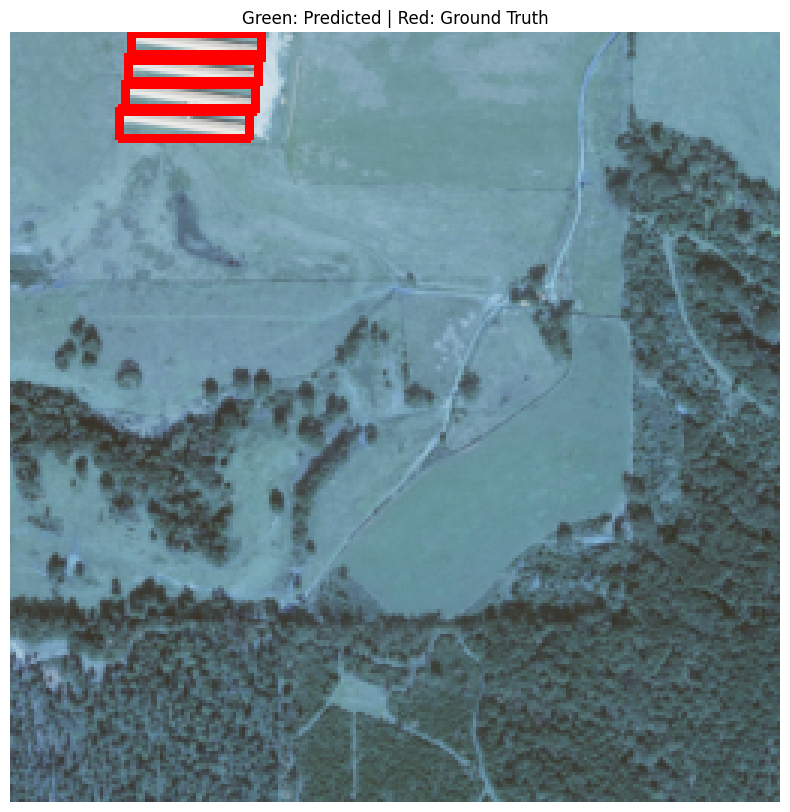

In [13]:
view_predictions(val_dataset, model, device)